# Projet Machine Learning 1 – Classification de la qualité du vin
##FERREOL Dorian et DOS SANTOS Mathéo
Objectif : prédire si un vin est **bon (qualité ≥ 7)** ou **pas bon** à partir de ses caractéristiques physico-chimiques.

In [ ]:
# Librairies utilisées dans tout le notebook
import numpy as np
np.set_printoptions(suppress=True)
import pandas as pd
import warnings
import matplotlib.pyplot as plt
import seaborn as sns          # pour la heatmap de corrélation et les boxplots par classe
warnings.filterwarnings('ignore')

# 2.1 Prétraitement des données

## Chargement des données et statistiques descriptives
Le jeu de données est fourni en 2 fichiers : vins rouges et vins blancs.
On les fusionne pour avoir plus d'exemples, et on ajoute une colonne `type` pour garder l'information de la couleur.

In [ ]:
# Les fichiers utilisent ';' comme séparateur
rouge = pd.read_csv('data/winequality-red.csv', sep=';')
blanc = pd.read_csv('data/winequality-white.csv', sep=';')

# On note la couleur de chaque vin avant de fusionner les deux tables
rouge['type'] = 'rouge'
blanc['type'] = 'blanc'

# Fusion des deux tables l'une sous l'autre
df = pd.concat([rouge, blanc], ignore_index=True)

print('Rouges :', rouge.shape, '| Blancs :', blanc.shape, '| Total :', df.shape)
df.head(3)

Rouges : (1599, 13) | Blancs : (4898, 13) | Total : (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,rouge
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,rouge
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,rouge


In [ ]:
# Type de chaque colonne : 11 variables numériques, quality (la note sur 10) et type (texte)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [ ]:
# Statistiques descriptives (moyenne, écart-type, min, quartiles, max) de chaque variable
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


Les échelles sont très différentes d'une variable à l'autre : `total sulfur dioxide` va jusqu'à 440
alors que `density` reste autour de 0.99. Il faudra normaliser les données avant les modèles basés sur des distances.

## Gestion des valeurs manquantes et détection des valeurs aberrantes

In [ ]:
# Nombre de valeurs manquantes par colonne
print(df.isnull().sum())

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
type                    0
dtype: int64


Aucune valeur manquante, il n'y a donc rien à remplacer ou supprimer de ce côté.

On vérifie aussi les **doublons** : un même vin présent plusieurs fois pourrait se retrouver
à la fois dans le train et dans le test, ce qui gonflerait artificiellement les scores.

In [ ]:
print('Nombre de doublons :', df.duplicated().sum())

# Suppression des doublons et renumérotation des lignes
df = df.drop_duplicates().reset_index(drop=True)
print('Taille après suppression :', df.shape)

Nombre de doublons : 1177
Taille après suppression : (5320, 13)


**Valeurs aberrantes :** on trace un boxplot par variable (les échelles sont trop différentes pour tout mettre
sur le même graphique). Les points en dehors des moustaches, c'est-à-dire en dehors de [Q1 − 1.5·IQR ; Q3 + 1.5·IQR],
sont considérés comme aberrants.

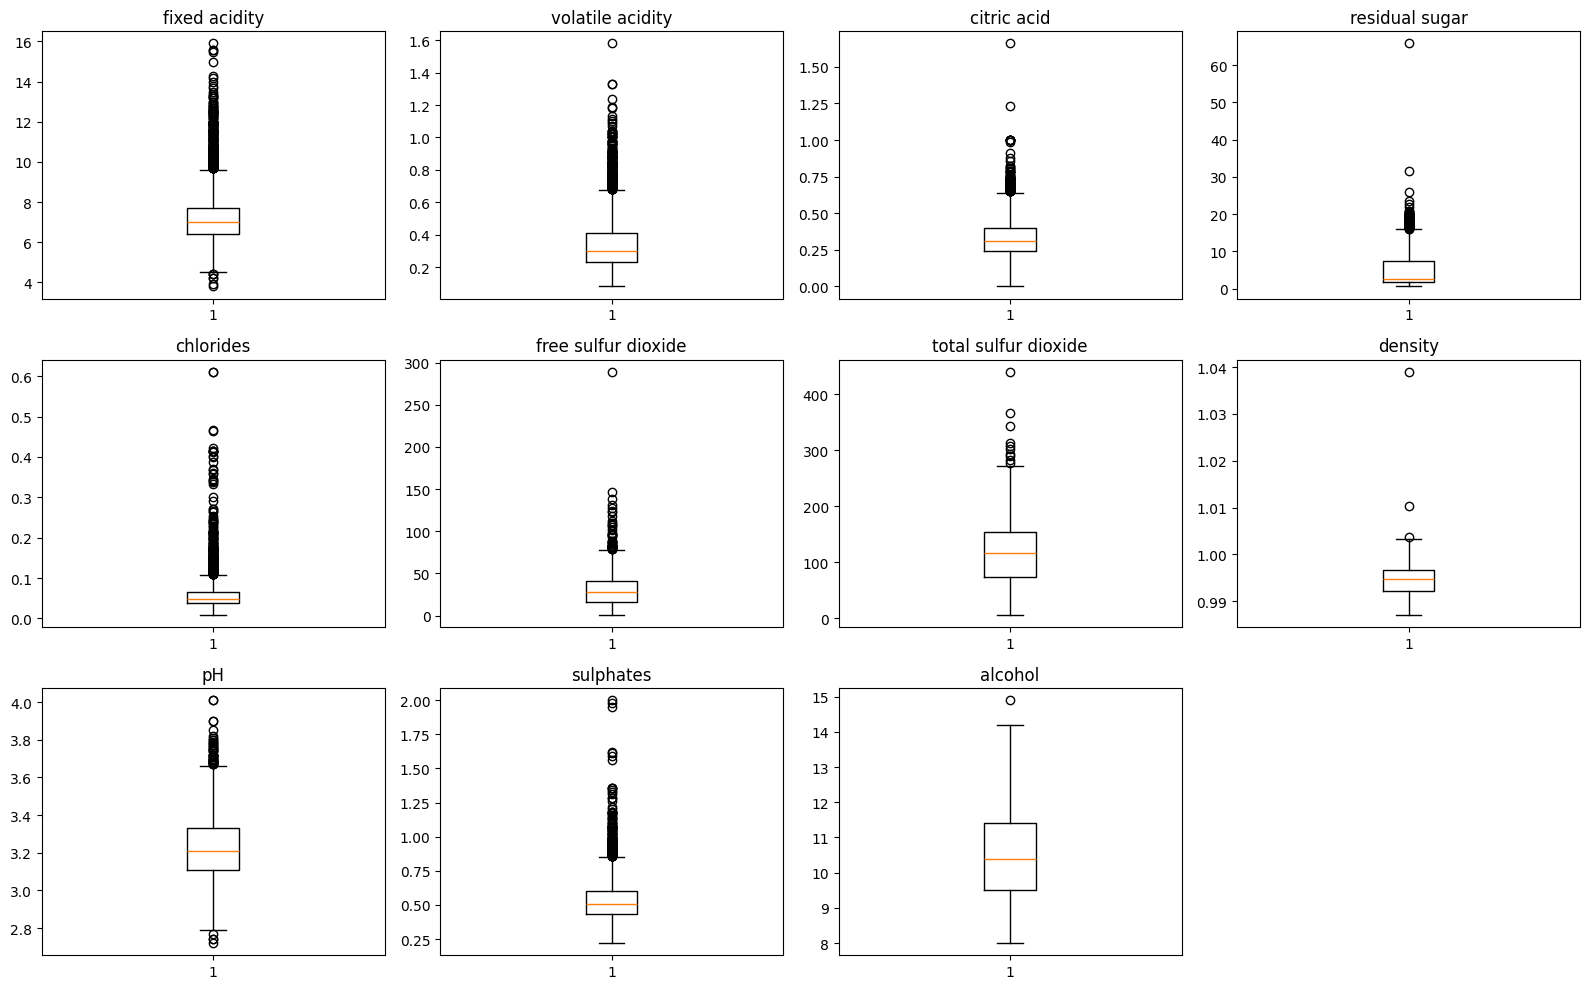

In [ ]:
# Les 11 variables physico-chimiques (on exclut quality et type)
variables = df.columns[:11]

# Un boxplot par variable, rangés dans une grille de 3 lignes x 4 colonnes
plt.figure(figsize=(16, 10))
for i, col in enumerate(variables):
    plt.subplot(3, 4, i + 1)
    plt.boxplot(df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [ ]:
# Calcul des bornes de la boxplot pour chaque variable
Q1 = df[variables].quantile(0.25)
Q3 = df[variables].quantile(0.75)
IQR = Q3 - Q1

# True si la valeur est en dehors des moustaches
aberrant = (df[variables] < Q1 - 1.5 * IQR) | (df[variables] > Q3 + 1.5 * IQR)

print('Valeurs aberrantes par variable :')
print(aberrant.sum())
print('\nVins avec au moins une valeur aberrante :', aberrant.any(axis=1).sum(), 'sur', len(df))

Valeurs aberrantes par variable :
fixed acidity           304
volatile acidity        279
citric acid             143
residual sugar          141
chlorides               237
free sulfur dioxide      44
total sulfur dioxide     10
density                   3
pH                       49
sulphates               163
alcohol                   1
dtype: int64

Vins avec au moins une valeur aberrante : 1094 sur 5320


**Décision : on garde les valeurs aberrantes.** Environ 1 vin sur 5 en a au moins une, les supprimer ferait perdre
beaucoup de données. Ce sont des mesures réelles de vins un peu extrêmes (ex : vins blancs très sucrés),
pas des erreurs de saisie.

## Encodage correct des variables catégorielles
La seule variable catégorielle est `type`, créée lors de la fusion. Les modèles ne travaillent qu'avec des nombres,
donc on la transforme en 0/1.

In [ ]:
# Seulement 2 catégories, un codage 0/1 suffit : rouge = 0, blanc = 1
df['type'] = df['type'].map({'rouge': 0, 'blanc': 1})
df['type'].value_counts()

,count
type,
1,3961
0,1359


## Transformation du problème en classification binaire
`quality` est une note sur 10 donnée par des experts. On crée la cible : qualité ≥ 7 donc bon vin.

In [ ]:
# 1 = bon vin (note >= 7), 0 = pas bon
df['bon_vin'] = (df['quality'] >= 7).astype(int)

# On supprime quality : si on la laissait, le modèle aurait directement la réponse
df = df.drop(columns=['quality'])

# X = variables d'entrée, Y = ce qu'on veut prédire
X = df.drop(columns=['bon_vin'])
Y = df['bon_vin']
print('X :', X.shape, '| Y :', Y.shape)

X : (5320, 12) | Y : (5320,)


## Analyse de la distribution des classes

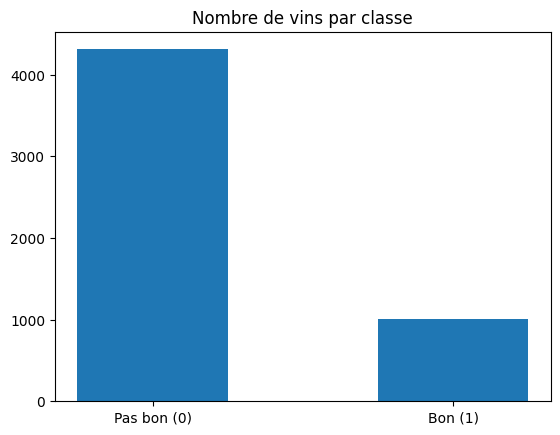

Bon vin : 0.190 et Pas bon : 0.810


In [ ]:
from collections import Counter

# Nombre de vins dans chaque classe
histogram = Counter(Y)
plt.bar(histogram.keys(), histogram.values(), 0.5)
plt.xticks([0, 1], ['Pas bon (0)', 'Bon (1)'])
plt.title('Nombre de vins par classe')
plt.show()

# Proportion de chaque classe
bon = np.sum(Y == 1) / len(Y)
pas_bon = np.sum(Y == 0) / len(Y)
print('Bon vin : {0:.3f} et Pas bon : {1:.3f}'.format(bon, pas_bon))

**Le jeu de données est déséquilibré (≈ 19 % de bons vins).** Un modèle qui répondrait toujours « pas bon »
aurait déjà ≈ 81 % d'accuracy sans rien apprendre. Pour évaluer les modèles, on regardera donc surtout
le rappel et le F1-score de la classe « bon vin ».

## Analyse des corrélations entre les variables
On utilise le coefficient de Pearson : entre −1 et 1, plus il est proche de ±1, plus le lien linéaire entre deux variables est fort.

In [ ]:
# Matrice de corrélation entre toutes les colonnes (variables + cible)
corr = df.corr()

In [ ]:
# Corrélation de chaque variable avec la cible, triée de la plus forte à la plus faible (en valeur absolue)
corr_cible = corr['bon_vin'].drop('bon_vin').sort_values(key=abs, ascending=False)
print(corr_cible)

alcohol                 0.417743
density                -0.294971
chlorides              -0.161027
volatile acidity       -0.144361
residual sugar         -0.084868
type                    0.081083
total sulfur dioxide   -0.067307
citric acid             0.060672
fixed acidity          -0.049841
pH                      0.048330
sulphates               0.036771
free sulfur dioxide     0.011325
Name: bon_vin, dtype: float64


In [ ]:
# Recherche des paires de variables très corrélées entre elles (|r| > 0.6) = information redondante
for i in range(len(X.columns)):
    for j in range(i + 1, len(X.columns)):
        r = corr.iloc[i, j]
        if abs(r) > 0.6:
            print(X.columns[i], '/', X.columns[j], ':', round(r, 2))

volatile acidity / type : -0.65
free sulfur dioxide / total sulfur dioxide : 0.72
total sulfur dioxide / type : 0.69
density / alcohol : -0.67


- `alcohol` est la variable la plus liée à la qualité (r ≈ 0.42) : plus un vin est alcoolisé, plus il a de chances d'être bon.
- Viennent ensuite `density` (−0.29), `chlorides` (−0.16) et `volatile acidity` (−0.14), qui jouent en négatif.
- Certaines variables sont redondantes : `free` / `total sulfur dioxide` (0.72) et `density` / `alcohol` (−0.67).
  Garder les deux apporte peu d'information en plus, ce qui justifie une sélection de variables.

## Visualisations (matrice de corrélation, histogrammes, boxplots)

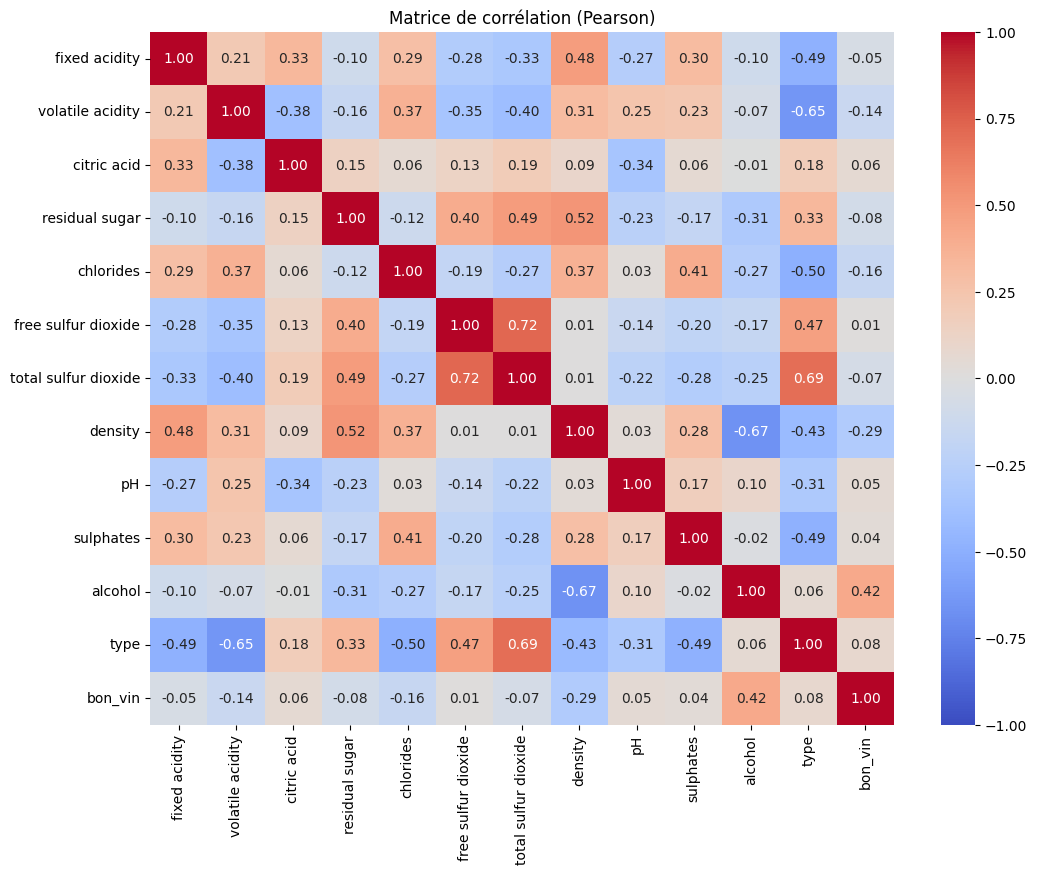

In [ ]:
# Matrice de corrélation sous forme de heatmap (rouge = corrélation positive, bleu = négative)
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matrice de corrélation (Pearson)')
plt.show()

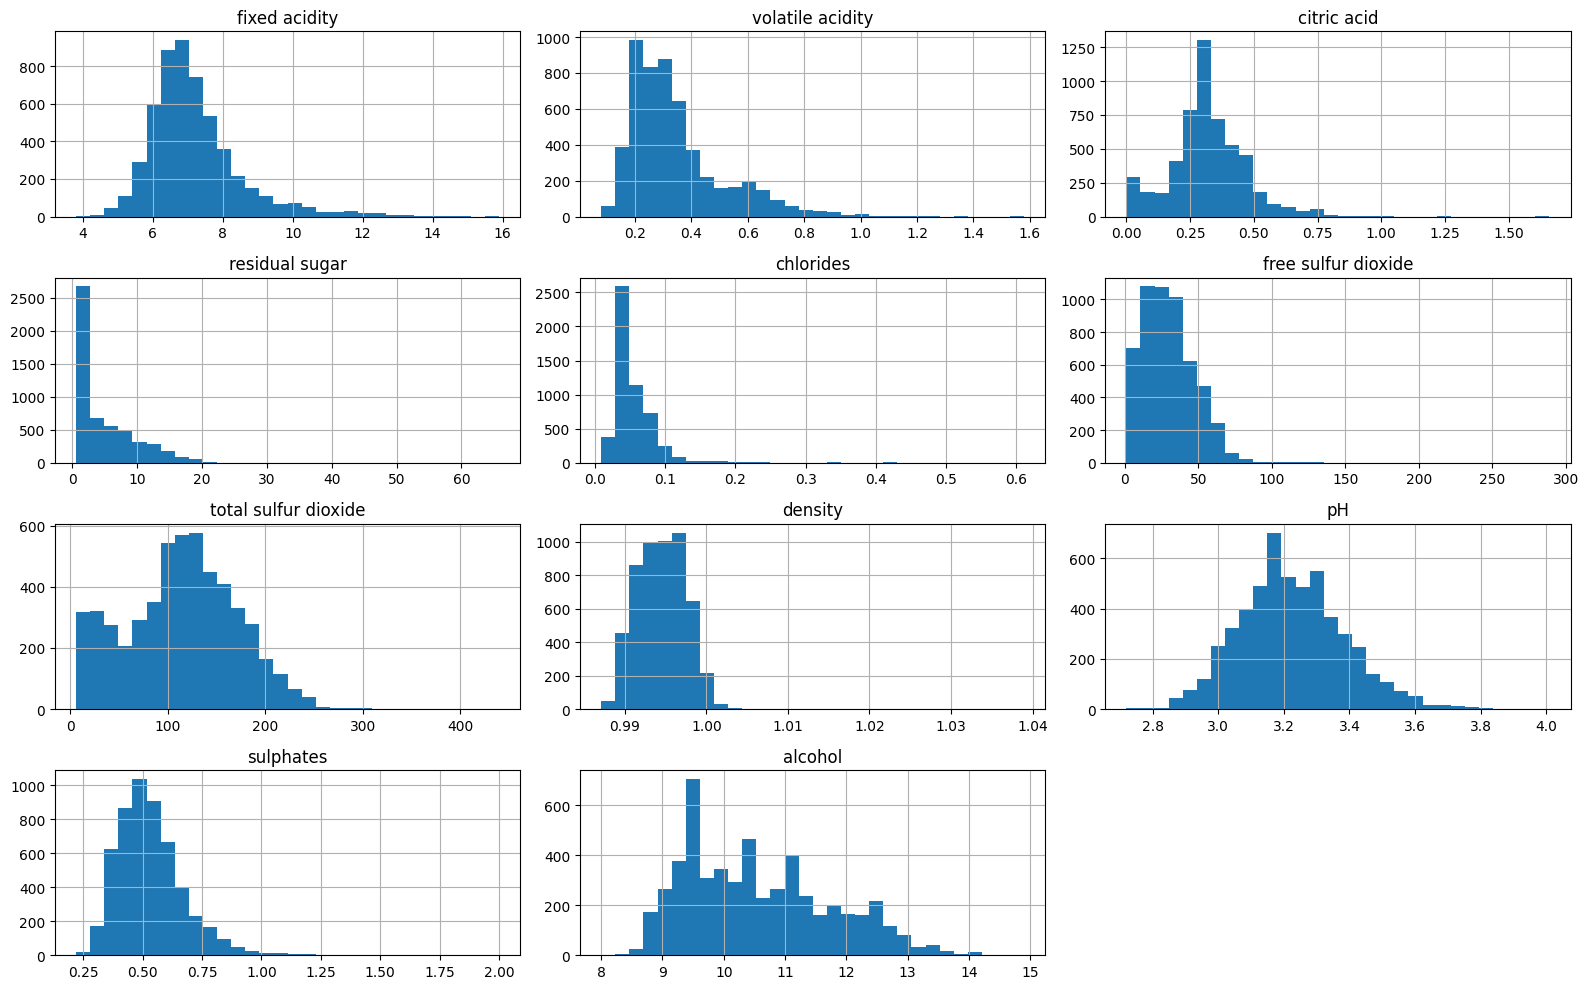

In [ ]:
# Histogrammes : forme de la distribution de chaque variable
df[variables].hist(bins=30, figsize=(16, 10))
plt.tight_layout()
plt.show()

La plupart des variables ne sont pas gaussiennes : elles sont étalées vers la droite
(`residual sugar`, `chlorides`, `volatile acidity`, `sulphates`…). C'est important pour Naive Bayes, qui suppose des distributions gaussiennes.

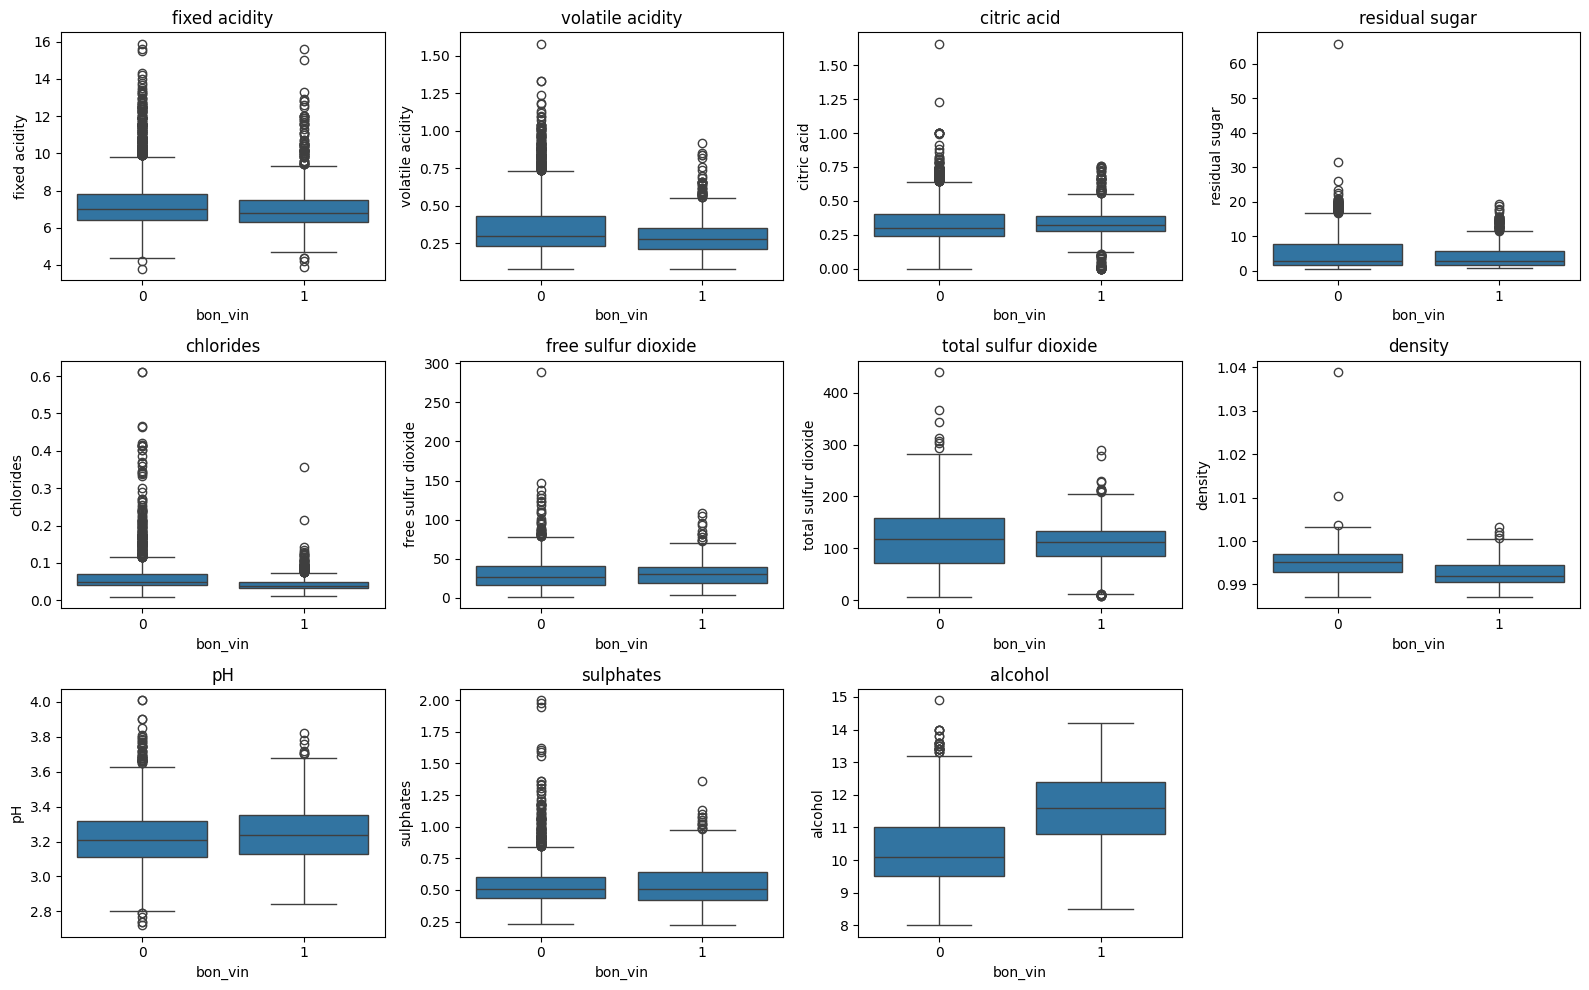

In [ ]:
# Boxplots par classe : on compare la distribution de chaque variable chez les bons et les mauvais vins
plt.figure(figsize=(16, 10))
for i, col in enumerate(variables):
    plt.subplot(3, 4, i + 1)
    sns.boxplot(x='bon_vin', y=col, data=df)
    plt.title(col)
plt.tight_layout()
plt.show()

Les bons vins ont nettement plus d'`alcohol` et une `density` plus faible, et un peu moins de `volatile acidity`
et de `chlorides`. Pour les autres variables, les boîtes des deux classes se chevauchent : elles séparent mal les classes.

```markdown
## Découpage Train/Test (Anti-Data Leakage)

On sépare les données avant la sélection de variables pour que le test reste totalement inconnu jusqu'à l'évaluation finale. La sélection est calculée uniquement sur le train, puis les mêmes colonnes seront appliquées au test.
```

In [ ]:
from sklearn.model_selection import train_test_split

# Découpage 75% train / 25% test stratifié sur la cible
Xtrain, Xtest, ytrain, ytest = train_test_split(X, Y, test_size=0.25, random_state=1, stratify=Y)

print('Train :', Xtrain.shape, '| Test :', Xtest.shape)
print('% bons vins train : {0:.3f} | test : {1:.3f}'.format(ytrain.mean(), ytest.mean()))

Train : (3990, 12) | Test : (1330, 12)
% bons vins train : 0.190 | test : 0.189


## Utilisation de méthodes de sélection de variables
On applique une méthode de chaque famille vue en cours, puis on fait voter les méthodes :
- **Filter** : coefficient de Pearson et information mutuelle (on note chaque variable seule)
- **Wrapper** : RFE (on teste des combinaisons de variables avec un modèle)
- **Embedded** : Lasso (la sélection se fait pendant l'entraînement grâce à la régularisation L1)

In [ ]:
from sklearn.preprocessing import StandardScaler

# RFE et Lasso comparent des coefficients : on normalise sur le train uniquement
ss = StandardScaler()
Xtrain_norm = pd.DataFrame(ss.fit_transform(Xtrain), columns=Xtrain.columns)

In [ ]:
# Cette cellule de normalisation préliminaire a été nettoyée car elle est maintenant gérée de manière unique plus haut

**Filter – Pearson** : on garde les variables dont la corrélation avec la cible dépasse 0.1 en valeur absolue.

In [ ]:
# Calcul de la corrélation uniquement sur les données d'entraînement
corr_train = Xtrain.join(ytrain).corr()
corr_train_cible = corr_train['bon_vin'].drop('bon_vin').sort_values(key=abs, ascending=False)

selection_pearson = corr_train_cible[abs(corr_train_cible) > 0.1].index.tolist()
print('Variables retenues (Pearson) :', selection_pearson)

Variables retenues (Pearson) : ['alcohol', 'density', 'chlorides', 'volatile acidity']


In [ ]:
# Cette cellule a été nettoyée car Pearson est calculé uniquement sur le train dans la nouvelle cellule f3851fe0

**Filter – Information mutuelle** : mesure l'information qu'une variable apporte sur la cible.
Contrairement à Pearson, elle détecte aussi les liens non linéaires (score = 0 si la variable n'apporte rien).

alcohol                 0.096591
density                 0.048188
chlorides               0.033243
total sulfur dioxide    0.023297
volatile acidity        0.019126
citric acid             0.015135
residual sugar          0.013918
sulphates               0.012688
fixed acidity           0.005946
pH                      0.002036
free sulfur dioxide     0.000000
type                    0.000000
dtype: float64


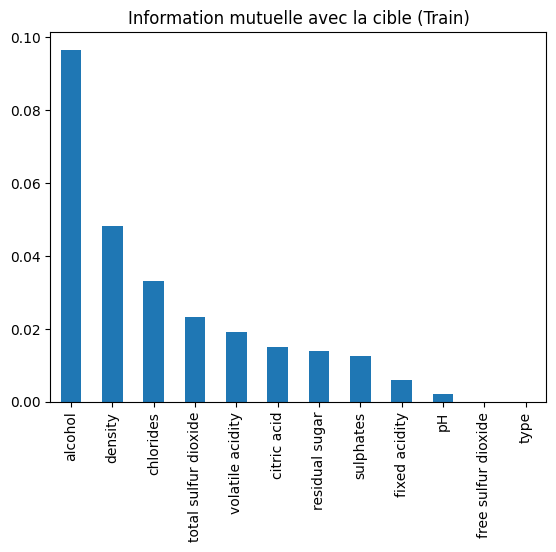

Variables retenues (Info mutuelle) : ['alcohol', 'density', 'chlorides', 'total sulfur dioxide']


In [ ]:
from sklearn.feature_selection import mutual_info_classif

# Calcul de l'information mutuelle uniquement sur le train
mi = mutual_info_classif(Xtrain, ytrain, random_state=0)
mi = pd.Series(mi, index=Xtrain.columns).sort_values(ascending=False)
print(mi)

mi.plot(kind='bar', title='Information mutuelle avec la cible (Train)')
plt.show()

selection_mi = mi[mi > mi.mean()].index.tolist()
print('Variables retenues (Info mutuelle) :', selection_mi)

In [ ]:
# Cette cellule a été nettoyée car l'information mutuelle est calculée uniquement sur le train dans la cellule a5bb1de7

**Wrapper – RFE (Recursive Feature Elimination)** : on entraîne une régression logistique, on retire la variable
la moins utile, et on recommence jusqu'à n'en garder que 6.

In [ ]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

# RFE entraîné uniquement sur le train normalisé
rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=6)
rfe.fit(Xtrain_norm, ytrain)

classement_rfe = pd.Series(rfe.ranking_, index=Xtrain.columns).sort_values()
print(classement_rfe)

selection_rfe = Xtrain.columns[rfe.support_].tolist()
print('\nVariables retenues (RFE) :', selection_rfe)

fixed acidity           1
volatile acidity        1
residual sugar          1
density                 1
alcohol                 1
pH                      1
sulphates               2
chlorides               3
total sulfur dioxide    4
free sulfur dioxide     5
type                    6
citric acid             7
dtype: int64

Variables retenues (RFE) : ['fixed acidity', 'volatile acidity', 'residual sugar', 'density', 'pH', 'alcohol']


In [ ]:
# Cette cellule a été nettoyée car l'algorithme RFE est exécuté uniquement sur le train dans la cellule e787d9fc

**Embedded – Lasso** : la pénalité L1 pousse les coefficients des variables inutiles à exactement 0.
Comme c'est un problème de classification, on l'applique à une régression logistique (`penalty='l1'`).

In [ ]:
# Lasso entraîné uniquement sur le train normalisé
lasso = LogisticRegression(penalty='l1', solver='liblinear', C=0.01)
lasso.fit(Xtrain_norm, ytrain)

coef_lasso = pd.Series(lasso.coef_[0], index=Xtrain.columns).sort_values(key=abs, ascending=False)
print(coef_lasso)

selection_lasso = coef_lasso[coef_lasso != 0].index.tolist()
print('\nVariables retenues (Lasso) :', selection_lasso)

alcohol                 0.832571
volatile acidity       -0.192509
sulphates               0.001625
fixed acidity           0.000000
residual sugar          0.000000
citric acid             0.000000
chlorides               0.000000
free sulfur dioxide     0.000000
density                 0.000000
total sulfur dioxide    0.000000
pH                      0.000000
type                    0.000000
dtype: float64

Variables retenues (Lasso) : ['alcohol', 'volatile acidity', 'sulphates']


In [ ]:
# Cette cellule a été nettoyée car l'algorithme Lasso est exécuté uniquement sur le train dans la cellule 2efd9b4b

**Bilan : vote des 4 méthodes**

In [ ]:
# Tableau récapitulatif des votes de sélection
bilan = pd.DataFrame(index=Xtrain.columns)
bilan['Pearson'] = [v in selection_pearson for v in Xtrain.columns]
bilan['Info mutuelle'] = [v in selection_mi for v in Xtrain.columns]
bilan['RFE'] = [v in selection_rfe for v in Xtrain.columns]
bilan['Lasso'] = [v in selection_lasso for v in Xtrain.columns]
bilan['Nb votes'] = bilan.sum(axis=1)
bilan = bilan.sort_values('Nb votes', ascending=False)
bilan

,Pearson,Info mutuelle,RFE,Lasso,Nb votes
alcohol,True,True,True,True,4
volatile acidity,True,False,True,True,3
density,True,True,True,False,3
chlorides,True,True,False,False,2
sulphates,False,False,False,True,1
residual sugar,False,False,True,False,1
fixed acidity,False,False,True,False,1
total sulfur dioxide,False,True,False,False,1
pH,False,False,True,False,1
citric acid,False,False,False,False,0


In [ ]:
# On retient les variables choisies par au moins 2 méthodes sur 4
variables_finales = bilan[bilan['Nb votes'] >= 2].index.tolist()
print('Variables finales :', variables_finales)
print('Nombre :', len(variables_finales), 'sur', X.shape[1])

X_selection = X[variables_finales]

Variables finales : ['alcohol', 'volatile acidity', 'density', 'chlorides']
Nombre : 4 sur 12


In [ ]:
# Sélection des variables finales de manière stricte
variables_finales = bilan[bilan['Nb votes'] >= 2].index.tolist()
print('Variables finales :', variables_finales)
print('Nombre :', len(variables_finales), 'sur', Xtrain.shape[1])

# Application des colonnes retenues sur le train et le test
Xtrain_sel = Xtrain[variables_finales]
Xtest_sel = Xtest[variables_finales]

Variables finales : ['alcohol', 'volatile acidity', 'density', 'chlorides']
Nombre : 4 sur 12


Les 4 méthodes sont d'accord sur `alcohol`. Avec au moins 2 votes, on retient `alcohol`, `volatile acidity`,
`density` et `chlorides`, ce qui est cohérent avec les corrélations et les boxplots.
On garde aussi `X` complet pour vérifier en 2.2 si cette sélection améliore ou non les modèles.

# 2.2 Modélisation et évaluation

## Modèles envisagés : régression logistique, k-NN, arbre de décision, Naive Bayes, SVM

**Séparation train / test** : 75 % des vins servent à entraîner les modèles, 25 % à les tester sur des vins jamais vus.
`stratify=Y` garde la même proportion de bons vins (≈ 19 %) dans les deux parties.

```markdown
**Le découpage train/test a été effectué avant la sélection de variables (voir section 2.1). Nous utilisons ici directement les variables séparées.**
```

In [ ]:
# Cette cellule a été nettoyée car le découpage train/test a déjà été fait au tout début

**Normalisation** : le scaler est calculé sur le train uniquement, puis appliqué au test.
Si on le calculait sur toutes les données, le test influencerait l'entraînement.

In [ ]:
# Version avec toutes les variables
ss = StandardScaler()
ss.fit(Xtrain)
Xtrain_norm = ss.transform(Xtrain)
Xtest_norm = ss.transform(Xtest)

# Version avec les variables sélectionnées
ss_sel = StandardScaler()
ss_sel.fit(Xtrain_sel)
Xtrain_sel_norm = ss_sel.transform(Xtrain_sel)
Xtest_sel_norm = ss_sel.transform(Xtest_sel)

**Création des modèles** : on les regroupe dans une fonction pour pouvoir créer des modèles neufs
et les entraîner sur les deux versions des données. Pour le SVM, on teste un noyau linéaire et un noyau RBF (non linéaire).

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report

def creer_modeles():
    return {
        'Régression logistique': LogisticRegression(max_iter=1000),
        'k-NN (k=5)': KNeighborsClassifier(n_neighbors=5),            # k=5 : valeur de départ conseillée en cours
        'Arbre de décision': DecisionTreeClassifier(criterion='entropy', random_state=0),
        'Naive Bayes': GaussianNB(),
        'SVM linéaire': SVC(kernel='linear'),
        'SVM RBF': SVC(kernel='rbf'),
    }

**Entraînement sur toutes les variables et premiers résultats**

In [ ]:
modeles = creer_modeles()

# Pour chaque modèle : entraînement sur le train, prédiction sur le test, matrice de confusion et rapport
for nom, modele in modeles.items():
    modele.fit(Xtrain_norm, ytrain)
    y_pred = modele.predict(Xtest_norm)
    print('************', nom, '************')
    print(confusion_matrix(ytest, y_pred))
    print(classification_report(ytest, y_pred))

************ Régression logistique ************
[[1024   54]
 [ 189   63]]
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      1078
           1       0.54      0.25      0.34       252

    accuracy                           0.82      1330
   macro avg       0.69      0.60      0.62      1330
weighted avg       0.79      0.82      0.79      1330

************ k-NN (k=5) ************
[[985  93]
 [138 114]]
              precision    recall  f1-score   support

           0       0.88      0.91      0.90      1078
           1       0.55      0.45      0.50       252

    accuracy                           0.83      1330
   macro avg       0.71      0.68      0.70      1330
weighted avg       0.82      0.83      0.82      1330

************ Arbre de décision ************
[[916 162]
 [143 109]]
              precision    recall  f1-score   support

           0       0.86      0.85      0.86      1078
           1       0.40      0.43  

**Toutes les variables vs variables sélectionnées** : on compare le F1-score de la classe « bon vin »
pour savoir si la sélection faite en 2.1 améliore les modèles.

In [ ]:
from sklearn.metrics import f1_score

modeles_sel = creer_modeles()
comparaison = []

for nom in modeles:
    # Entraînement des mêmes modèles mais avec seulement les variables sélectionnées
    modeles_sel[nom].fit(Xtrain_sel_norm, ytrain)
    f1_complet = f1_score(ytest, modeles[nom].predict(Xtest_norm))
    f1_sel = f1_score(ytest, modeles_sel[nom].predict(Xtest_sel_norm))
    comparaison.append([nom, f1_complet, f1_sel])

comparaison = pd.DataFrame(comparaison, columns=['Modèle', 'F1 (12 variables)', 'F1 (4 variables)'])
comparaison.round(3)

,Modèle,F1 (12 variables),F1 (4 variables)
0,Régression logistique,0.341,0.311
1,k-NN (k=5),0.497,0.389
2,Arbre de décision,0.417,0.392
3,Naive Bayes,0.493,0.474
4,SVM linéaire,0.000,0.000
5,SVM RBF,0.368,0.255


Avec seulement 4 variables, le F1 baisse pour tous les modèles (ex : k-NN 0.50 → 0.39) : les variables écartées
apportent quand même de l'information. **On garde donc les 12 variables pour la suite.**
La sélection de la 2.1 reste utile pour comprendre quelles variables comptent le plus.

## Justification du choix des modèles

| Modèle | Propriétés théoriques | Adaptabilité à nos données |
|---|---|---|
| Régression logistique | **Linéaire** : frontière de décision = hyperplan, sortie = probabilité (sigmoïde) | Simple et rapide, sert de modèle de référence. Peut manquer des relations non linéaires. |
| k-NN | **Non linéaire** : classe un vin selon ses k voisins les plus proches | Basé sur les distances → normalisation obligatoire. Sensible au bruit et aux valeurs aberrantes, qu'on a gardées. |
| Arbre de décision | **Non linéaire** : suite de tests sur les variables | Pas besoin de normalisation, peu sensible aux valeurs aberrantes, facile à interpréter. Risque fort de sur-apprentissage. |
| Naive Bayes | **Probabiliste** (théorème de Bayes) | Suppose des variables indépendantes et gaussiennes. Or nos variables sont corrélées et pas gaussiennes → hypothèses non respectées. |
| SVM linéaire | **Linéaire** : hyperplan à marge maximale | Mêmes limites que la régression logistique. |
| SVM RBF | **Non linéaire** grâce au noyau | Frontière courbe, plus puissant, mais plus lent et sensible aux hyperparamètres C et gamma. |

Ces modèles couvrent les deux familles (linéaires / non linéaires), ce qui permet de voir si le problème a besoin d'une frontière complexe.

# 2.3 Évaluation des modèles
On continue avec toutes les variables.

## Évaluation à l'aide de métriques pertinentes : accuracy, précision, rappel, F1-score
- **Accuracy** : part de bonnes prédictions au total
- **Précision** : parmi les vins prédits « bons », part de vins vraiment bons
- **Rappel** : parmi les vrais bons vins, part de vins retrouvés
- **F1-score** : moyenne harmonique de la précision et du rappel
- **AUC** : aire sous la courbe ROC (1 = parfait, 0.5 = hasard)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, roc_curve

# La courbe ROC a besoin d'un score continu (pas seulement 0/1) :
# predict_proba si le modèle le propose, sinon decision_function (cas du SVM)
def score_continu(modele, X):
    if hasattr(modele, 'predict_proba'):
        return modele.predict_proba(X)[:, 1]
    return modele.decision_function(X)

# Calcul de toutes les métriques pour chaque modèle
resultats = []
for nom, modele in modeles.items():
    y_pred = modele.predict(Xtest_norm)
    resultats.append([nom,
                      accuracy_score(ytest, y_pred),
                      precision_score(ytest, y_pred, zero_division=0),
                      recall_score(ytest, y_pred),
                      f1_score(ytest, y_pred),
                      roc_auc_score(ytest, score_continu(modele, Xtest_norm))])

resultats = pd.DataFrame(resultats, columns=['Modèle', 'Accuracy', 'Précision', 'Rappel', 'F1', 'AUC'])
resultats.round(3)

,Modèle,Accuracy,Précision,Rappel,F1,AUC
0,Régression logistique,0.817,0.538,0.250,0.341,0.822
1,k-NN (k=5),0.826,0.551,0.452,0.497,0.796
2,Arbre de décision,0.771,0.402,0.433,0.417,0.641
3,Naive Bayes,0.744,0.394,0.659,0.493,0.765
4,SVM linéaire,0.811,0.000,0.000,0.000,0.804
5,SVM RBF,0.829,0.617,0.262,0.368,0.812


## Matrice de confusion

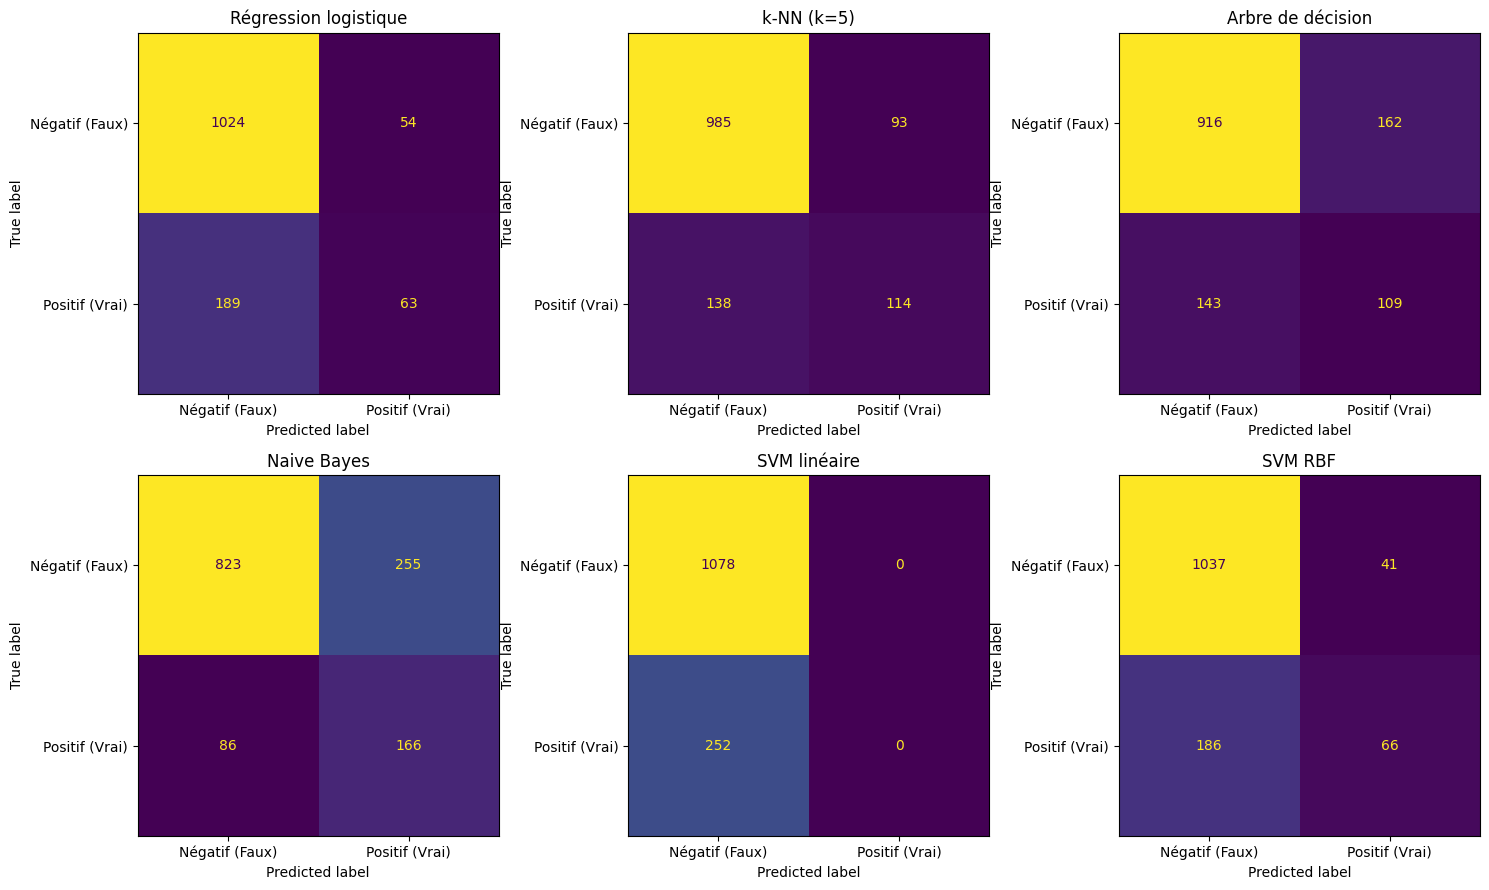

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# Une matrice de confusion par modèle (lignes = vraie classe, colonnes = classe prédite)
plt.figure(figsize=(15, 9))
for i, (nom, modele) in enumerate(modeles.items()):
    ax = plt.subplot(2, 3, i + 1)
    ConfusionMatrixDisplay.from_predictions(
        ytest,
        modele.predict(Xtest_norm),
        ax=ax,
        colorbar=False,
        display_labels=['Négatif (Faux)', 'Positif (Vrai)']
    )
    ax.set_title(nom)
plt.tight_layout()
plt.show()

Le SVM linéaire prédit **tous** les vins comme « pas bons » (0 vrai positif), et pourtant il a 81 % d'accuracy,
exactement la proportion de « pas bons ». C'est la preuve que l'accuracy seule est trompeuse sur un jeu déséquilibré.
La régression logistique et le SVM RBF ne retrouvent qu'environ 1 bon vin sur 4.

## Courbe ROC et AUC
La courbe ROC montre le taux de vrais positifs en fonction du taux de faux positifs pour **tous les seuils** de décision possibles.

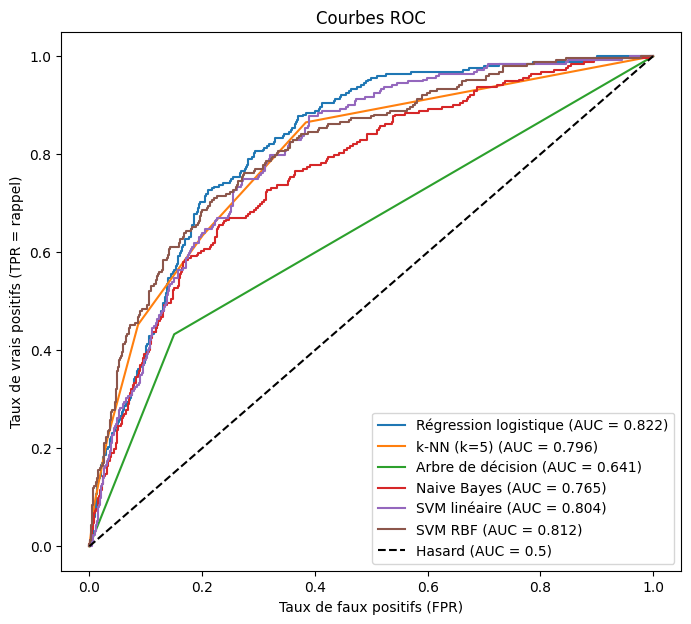

In [ ]:
plt.figure(figsize=(8, 7))
for nom, modele in modeles.items():
    scores = score_continu(modele, Xtest_norm)
    fpr, tpr, seuils = roc_curve(ytest, scores)   # points de la courbe pour chaque seuil
    plt.plot(fpr, tpr, label='{0} (AUC = {1:.3f})'.format(nom, roc_auc_score(ytest, scores)))

# Diagonale = modèle qui répond au hasard
plt.plot([0, 1], [0, 1], 'k--', label='Hasard (AUC = 0.5)')
plt.xlabel('Taux de faux positifs (FPR)')
plt.ylabel('Taux de vrais positifs (TPR = rappel)')
plt.title('Courbes ROC')
plt.legend()
plt.show()

La régression logistique et les deux SVM ont une bonne AUC (≈ 0.80–0.82) malgré un rappel faible :
ils savent **classer** les vins (les bons ont un score plus élevé), mais le seuil par défaut est mal placé
à cause du déséquilibre. L'arbre de décision a la plus faible AUC (0.64).

## Comparaison des performances et interprétation des résultats

In [ ]:
# Classement des modèles selon le F1-score (notre métrique principale à cause du déséquilibre)
resultats.sort_values('F1', ascending=False).round(3)

,Modèle,Accuracy,Précision,Rappel,F1,AUC
1,k-NN (k=5),0.826,0.551,0.452,0.497,0.796
3,Naive Bayes,0.744,0.394,0.659,0.493,0.765
2,Arbre de décision,0.771,0.402,0.433,0.417,0.641
5,SVM RBF,0.829,0.617,0.262,0.368,0.812
0,Régression logistique,0.817,0.538,0.250,0.341,0.822
4,SVM linéaire,0.811,0.000,0.000,0.000,0.804


- **k-NN (k=5)** et **Naive Bayes** ont le meilleur F1 (≈ 0.50). Naive Bayes a le meilleur rappel (0.66) mais une précision faible :
  il prédit « bon » trop souvent.
- **Régression logistique** et **SVM RBF** ont une bonne précision et une bonne AUC, mais ratent trois bons vins sur quatre.
- **SVM linéaire** est inutilisable en l'état (rappel = 0).
- Les modèles non linéaires (k-NN, SVM RBF) font mieux que leurs équivalents linéaires : la frontière entre bons et mauvais vins n'est pas une simple droite.

## Identification du modèle le plus performant selon un compromis biais/variance
On compare le F1 sur le train et sur le test :
- grand écart train/test → **variance élevée** (sur-apprentissage : le modèle apprend le train par cœur) ;
- train et test faibles tous les deux → **biais élevé** (sous-apprentissage : le modèle est trop simple).

In [ ]:
biais_variance = []
for nom, modele in modeles.items():
    f1_train = f1_score(ytrain, modele.predict(Xtrain_norm))
    f1_test = f1_score(ytest, modele.predict(Xtest_norm))
    biais_variance.append([nom, f1_train, f1_test, f1_train - f1_test])

biais_variance = pd.DataFrame(biais_variance, columns=['Modèle', 'F1 train', 'F1 test', 'Écart'])
biais_variance.round(3)

,Modèle,F1 train,F1 test,Écart
0,Régression logistique,0.406,0.341,0.065
1,k-NN (k=5),0.646,0.497,0.149
2,Arbre de décision,1.000,0.417,0.583
3,Naive Bayes,0.493,0.493,-0.001
4,SVM linéaire,0.000,0.000,0.000
5,SVM RBF,0.448,0.368,0.080


- **Arbre de décision** : F1 train = 1.00 et F1 test = 0.42 → **variance élevée**.
- **Régression logistique / SVM** : train et test faibles et proches → **biais élevé** (frontière trop simple).
- **Naive Bayes** : aucun écart mais F1 moyen → stable, avec un biais dû à ses hypothèses non respectées.
- **k-NN (k=5)** : meilleur F1 test avec un écart raisonnable → **meilleur compromis biais/variance avant optimisation.**

# 2.4 Optimisation des hyperparamètres
Chaque combinaison d'hyperparamètres est évaluée par **validation croisée à 5 plis** sur le train uniquement :
le test reste intouché jusqu'à la fin. On optimise le **F1-score** et pas l'accuracy, à cause du déséquilibre.

Naive Bayes n'a pas de vrai hyperparamètre à régler, on ne l'optimise donc pas.
Pour le SVM, on optimise le noyau RBF (le linéaire ne détecte aucun bon vin).

In [ ]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_score
import time

## Grid Search : recherche exhaustive sur une grille d'hyperparamètres

**Régression logistique** : on cherche le meilleur C (C petit = régularisation forte).

In [ ]:
grid_lr = GridSearchCV(LogisticRegression(max_iter=1000),
                       {'C': [0.01, 0.1, 1, 10, 100]},
                       cv=5, scoring='f1')
grid_lr.fit(Xtrain_norm, ytrain)
print('Meilleur C :', grid_lr.best_params_, '| F1 en validation croisée : {0:.3f}'.format(grid_lr.best_score_))

Meilleur C : {'C': 0.1} | F1 en validation croisée : 0.406


**k-NN** : on cherche le meilleur nombre de voisins k.

Meilleur k : {'n_neighbors': 1} | F1 en validation croisée : 0.503


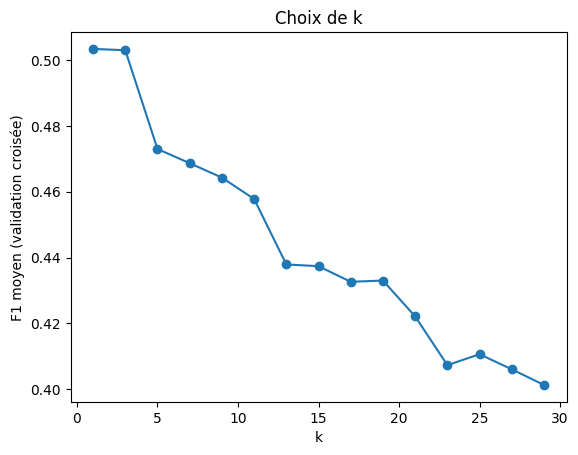

In [ ]:
grid_knn = GridSearchCV(KNeighborsClassifier(),
                        {'n_neighbors': list(range(1, 31, 2))},   # k impairs de 1 à 29 (impair = pas d'égalité au vote)
                        cv=5, scoring='f1')
grid_knn.fit(Xtrain_norm, ytrain)
print('Meilleur k :', grid_knn.best_params_, '| F1 en validation croisée : {0:.3f}'.format(grid_knn.best_score_))

# F1 moyen en fonction de k (méthode du coude)
plt.plot(range(1, 31, 2), grid_knn.cv_results_['mean_test_score'], marker='o')
plt.xlabel('k')
plt.ylabel('F1 moyen (validation croisée)')
plt.title('Choix de k')
plt.show()

Le Grid Search choisit k = 1, mais un k aussi petit donne une variance élevée (le modèle colle au bruit).
On le vérifiera avec la validation croisée et le test plus bas.

**SVM RBF** : on cherche le meilleur couple (C, gamma) parmi 4 × 4 = 16 combinaisons.

In [ ]:
grille_svm = {'C': [0.1, 1, 10, 100],              # C grand = moins d'erreurs tolérées sur le train
              'gamma': ['scale', 0.01, 0.1, 1]}    # gamma grand = frontière plus tordue

debut = time.time()
grid_svm = GridSearchCV(SVC(kernel='rbf'), grille_svm, cv=5, scoring='f1')
grid_svm.fit(Xtrain_norm, ytrain)
temps_grid = time.time() - debut

print('Meilleurs paramètres :', grid_svm.best_params_, '| F1 en validation croisée : {0:.3f}'.format(grid_svm.best_score_))
print('Temps : {0:.1f} s'.format(temps_grid))

Meilleurs paramètres : {'C': 100, 'gamma': 'scale'} | F1 en validation croisée : 0.474
Temps : 24.5 s


## Random Search : recherche aléatoire pour un gain de temps

**Arbre de décision** : il y a 2 × 19 × 20 = 760 combinaisons possibles, trop pour tout tester.
On en tire 30 au hasard.

In [ ]:
random_dt = RandomizedSearchCV(DecisionTreeClassifier(random_state=0),
                               {'criterion': ['gini', 'entropy'],
                                'max_depth': list(range(2, 21)),         # profondeur max : limite le sur-apprentissage
                                'min_samples_leaf': list(range(1, 21))},  # nombre minimum de vins par feuille
                               n_iter=30, cv=5, scoring='f1', random_state=0)
random_dt.fit(Xtrain_norm, ytrain)
print('Meilleurs paramètres :', random_dt.best_params_, '| F1 en validation croisée : {0:.3f}'.format(random_dt.best_score_))

Meilleurs paramètres : {'min_samples_leaf': 13, 'max_depth': 16, 'criterion': 'entropy'} | F1 en validation croisée : 0.460


**SVM RBF** : même grille que le Grid Search, mais on ne teste que 6 combinaisons sur 16, pour comparer le temps de calcul.

In [ ]:
debut = time.time()
random_svm = RandomizedSearchCV(SVC(kernel='rbf'), grille_svm, n_iter=6, cv=5, scoring='f1', random_state=0)
random_svm.fit(Xtrain_norm, ytrain)
temps_random = time.time() - debut

print('Grid Search   : 16 combinaisons, {0:.1f} s, meilleur F1 = {1:.3f}, {2}'.format(temps_grid, grid_svm.best_score_, grid_svm.best_params_))
print('Random Search :  6 combinaisons, {0:.1f} s, meilleur F1 = {1:.3f}, {2}'.format(temps_random, random_svm.best_score_, random_svm.best_params_))

Grid Search   : 16 combinaisons, 24.5 s, meilleur F1 = 0.474, {'C': 100, 'gamma': 'scale'}
Random Search :  6 combinaisons, 6.8 s, meilleur F1 = 0.441, {'gamma': 'scale', 'C': 10}


Le Random Search est environ 4 fois plus rapide, pour un score un peu plus faible car il n'a pas testé la meilleure combinaison.
Sur une petite grille, le Grid Search reste faisable ; le Random Search devient intéressant quand la grille est grande.

## Évaluation des modèles optimisés via validation croisée (k-fold)
Pour chaque modèle optimisé, on refait une validation croisée à 5 plis sur le train :
la **moyenne** donne la performance et l'**écart-type** donne la stabilité du modèle.
On termine par le score sur le test.

In [ ]:
modeles_opt = {
    'Régression logistique': grid_lr.best_estimator_,
    'k-NN': grid_knn.best_estimator_,
    'Arbre de décision': random_dt.best_estimator_,
    'Naive Bayes': GaussianNB(),
    'SVM RBF': grid_svm.best_estimator_,
}

resultats_opt = []
for nom, modele in modeles_opt.items():
    # Validation croisée 5 plis sur le train
    cv = cross_val_score(modele, Xtrain_norm, ytrain, cv=5, scoring='f1')

    # Entraînement final sur tout le train puis évaluation sur le test
    modele.fit(Xtrain_norm, ytrain)
    y_pred = modele.predict(Xtest_norm)
    resultats_opt.append([nom, cv.mean(), cv.std(),
                          f1_score(ytrain, modele.predict(Xtrain_norm)),
                          f1_score(ytest, y_pred),
                          recall_score(ytest, y_pred),
                          roc_auc_score(ytest, score_continu(modele, Xtest_norm))])

resultats_opt = pd.DataFrame(resultats_opt, columns=['Modèle', 'F1 CV moyen', 'F1 CV écart-type',
                                                     'F1 train', 'F1 test', 'Rappel test', 'AUC test'])
resultats_opt.round(3)

,Modèle,F1 CV moyen,F1 CV écart-type,F1 train,F1 test,Rappel test,AUC test
0,Régression logistique,0.406,0.023,0.405,0.341,0.246,0.821
1,k-NN,0.503,0.028,1.000,0.446,0.440,0.658
2,Arbre de décision,0.460,0.020,0.656,0.402,0.369,0.735
3,Naive Bayes,0.492,0.035,0.493,0.493,0.659,0.765
4,SVM RBF,0.474,0.041,0.748,0.428,0.353,0.799


**Conclusion de l'optimisation :**
- **k-NN** : k = 1 sur-apprend (F1 train = 1.00, AUC test = 0.66), ce qui confirme qu'un petit k donne une variance élevée.
  La courbe montre que k = 3 a le même F1 en validation croisée, et k = 5 reste meilleur sur le test.
- **Arbre** : limiter la profondeur et la taille des feuilles réduit le sur-apprentissage (F1 train 1.00 → 0.66) et l'AUC passe de 0.64 à 0.74.
- **SVM RBF** : le F1 test passe de 0.37 à 0.43, avec un meilleur rappel.
- **Régression logistique** : pas de gain, c'est la limite d'un modèle linéaire (biais).

**Limite principale :** même optimisés, aucun modèle ne dépasse ≈ 0.50 de F1, et la plupart ratent plus de la moitié
des bons vins. L'optimisation des hyperparamètres ne suffit pas : le problème vient du déséquilibre des classes.

## Prise en compte du déséquilibre des classes
**Le problème (vu dans les matrices de confusion en 2.3) :** les modèles produisent beaucoup de **faux négatifs**,
c'est-à-dire des bons vins prédits « pas bons ». Or notre objectif est justement de détecter les bons vins.

**Pourquoi :** pendant l'entraînement, le modèle voit environ 4 fois plus de mauvais vins que de bons.
Pour faire le moins d'erreurs possible au total, il a intérêt à répondre « pas bon » quand il hésite.
L'AUC ≈ 0.80 montre pourtant qu'il sait distinguer les deux classes : c'est sa décision qui est trop prudente.

**La correction :** l'option `class_weight='balanced'` donne plus de poids aux bons vins pendant l'entraînement
(une erreur sur un bon vin compte environ 4 fois plus). On ne touche pas aux données :
le test reste déséquilibré car il doit refléter la réalité.

On l'applique aux modèles qui proposent cette option (régression logistique, arbre de décision, SVM),
en gardant les hyperparamètres trouvés juste avant. k-NN et Naive Bayes n'ont pas cette option.

In [ ]:
# Mêmes modèles que les modèles optimisés, avec en plus class_weight='balanced'
modeles_bal = {
    'Régression logistique': LogisticRegression(max_iter=1000, class_weight='balanced', **grid_lr.best_params_),
    'Arbre de décision': DecisionTreeClassifier(random_state=0, class_weight='balanced', **random_dt.best_params_),
    'SVM RBF': SVC(kernel='rbf', class_weight='balanced', **grid_svm.best_params_),
}

avant_apres = []
for nom, modele in modeles_bal.items():
    modele.fit(Xtrain_norm, ytrain)

    # Prédictions du modèle optimisé sans correction (avant) et avec correction (après)
    y_avant = modeles_opt[nom].predict(Xtest_norm)
    y_apres = modele.predict(Xtest_norm)

    for version, y_pred in [('avant', y_avant), ('après', y_apres)]:
        avant_apres.append([nom, version,
                            accuracy_score(ytest, y_pred),
                            precision_score(ytest, y_pred),
                            recall_score(ytest, y_pred),
                            f1_score(ytest, y_pred),
                            confusion_matrix(ytest, y_pred)[1, 0]])   # case en bas à gauche = faux négatifs

avant_apres = pd.DataFrame(avant_apres, columns=['Modèle', 'Version', 'Accuracy', 'Précision',
                                                 'Rappel', 'F1', 'Faux négatifs'])
avant_apres.round(3)

,Modèle,Version,Accuracy,Précision,Rappel,F1,Faux négatifs
0,Régression logistique,avant,0.820,0.554,0.246,0.341,190
1,Régression logistique,après,0.726,0.390,0.786,0.521,54
2,Arbre de décision,avant,0.792,0.441,0.369,0.402,159
3,Arbre de décision,après,0.731,0.380,0.663,0.483,85
4,SVM RBF,avant,0.821,0.543,0.353,0.428,163
5,SVM RBF,après,0.771,0.435,0.702,0.537,75


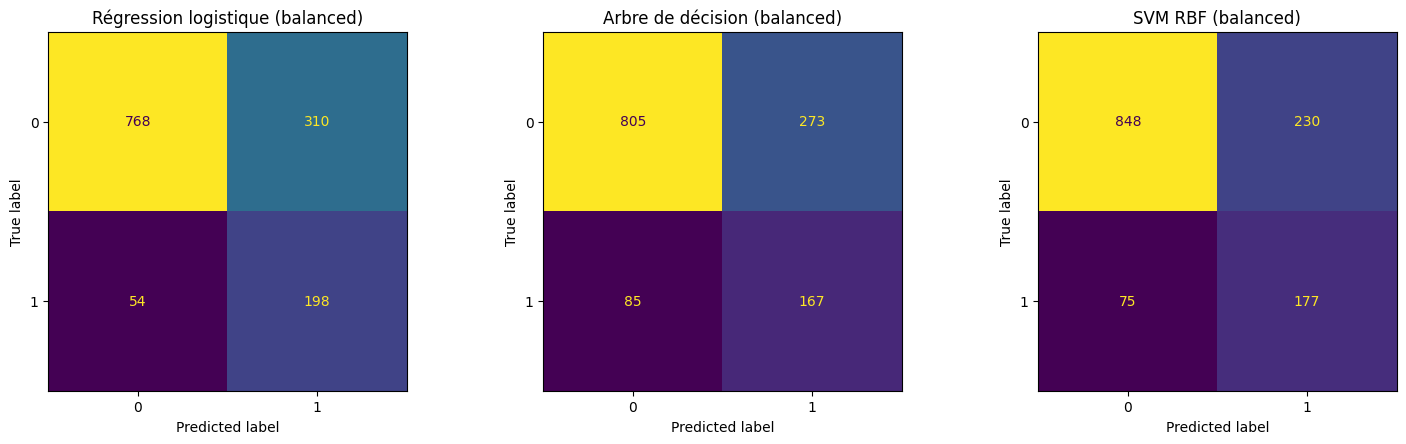

In [ ]:
# Matrices de confusion des modèles corrigés : la case en bas à gauche (faux négatifs) doit diminuer
plt.figure(figsize=(15, 4.5))
for i, (nom, modele) in enumerate(modeles_bal.items()):
    ax = plt.subplot(1, 3, i + 1)
    ConfusionMatrixDisplay.from_predictions(ytest, modele.predict(Xtest_norm), ax=ax, colorbar=False)
    ax.set_title(nom + ' (balanced)')
plt.tight_layout()
plt.show()

In [ ]:
# Vérification par validation croisée (5 plis) : le gain doit aussi se voir sur le train, pas seulement sur le test
for nom, modele in modeles_bal.items():
    cv_avant = cross_val_score(modeles_opt[nom], Xtrain_norm, ytrain, cv=5, scoring='f1')
    cv_apres = cross_val_score(modele, Xtrain_norm, ytrain, cv=5, scoring='f1')
    print('{0:<22} F1 CV avant : {1:.3f} | après : {2:.3f}'.format(nom, cv_avant.mean(), cv_apres.mean()))

Régression logistique  F1 CV avant : 0.406 | après : 0.543
Arbre de décision      F1 CV avant : 0.460 | après : 0.490
SVM RBF                F1 CV avant : 0.474 | après : 0.531


**Résultats :**
- Le nombre de **faux négatifs** chute pour les 3 modèles (ex : régression logistique 190 → 54 bons vins ratés sur 252).
- Le **rappel** fait un bond (régression logistique 0.25 → 0.79, SVM RBF 0.35 → 0.70) et le **F1** augmente partout.
- En contrepartie, la précision et l'accuracy baissent : le modèle prédit « bon » plus souvent, donc il se trompe aussi
  plus souvent sur des vins moyens. C'est un compromis acceptable car notre objectif est de **trouver les bons vins**.
- La validation croisée confirme le gain : ce n'est pas un hasard du découpage train/test.

## Conclusion finale
**Modèle retenu : SVM RBF optimisé avec `class_weight='balanced'`**
(C = 100, gamma = 'scale') : meilleur F1 sur le test (≈ 0.54), un F1 en validation croisée du même niveau (≈ 0.53),
et il retrouve 7 bons vins sur 10.
La régression logistique corrigée est très proche (meilleur rappel ≈ 0.79) et reste une alternative plus simple et plus rapide.

Le point clé du projet : sur un jeu de données déséquilibré, l'accuracy est trompeuse. Il faut regarder le rappel
et le F1 de la classe minoritaire, et corriger le déséquilibre pendant l'entraînement.